# Week 2 — Overture missingness bias

**From meeting 1.** Are missing building-use tags biased toward residential, non-residential, or both? This has to enter the **experimental design**, not stay as an EDA finding.

An unlabeled Overture footprint has no class. So we cannot answer the question from Overture alone. We join **independent occupancy layers** onto the same buildings, then compare:

\[
P(\text{residential} \mid \text{unlabeled})
\quad\text{vs}\quad
P(\text{residential} \mid \text{labeled})
\]

**How to read it**

- Shares are **similar** → the gap is **coverage** (OSM tags vs Microsoft/Google ML roofprints), not class bias.
- Unlabeled is **much more residential** (or the reverse) → class bias. That city needs different sampling or exclusion.

Literature already says the direction **flips by city** (Atwal et al., *Sci Rep* 2022; Herfort et al., *Nat Commun* 2023; Bae & Biljecki 2023). Notebook 06: 68% of US cities are under 5% tagged; 8% of cities hold 62% of tagged buildings.

**Sample.** Same 9 US metros as notebooks 02 / 09, plus the ~39 km hinterland, **labeled and unlabeled**. Unlabeled footprints are never treated as negatives.

**Not this notebook.** Eyeball QA and the gold / transfer / inference-only city list come next.


## Setup


In [1]:
from __future__ import annotations

import json
import os
import time
import warnings
from pathlib import Path
from urllib.parse import quote
from urllib.request import urlopen, urlretrieve

%matplotlib inline

import duckdb
import ee
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_rows", 80)
pd.set_option("display.float_format", lambda x: f"{x:0.3f}")

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#fbfcfe",
    "axes.grid": True,
    "grid.alpha": 0.28,
    "grid.linestyle": ":",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "semibold",
    "font.size": 10,
})

ROOT = Path(".").resolve()
for cand in (ROOT, ROOT.parent, ROOT.parent.parent):
    if (cand / "requirements.txt").exists():
        ROOT = cand
        break

OUT_DIR = ROOT / "outputs" / "week2_missingness"
OUT_DIR.mkdir(parents=True, exist_ok=True)
DOU_CACHE = ROOT / "outputs" / "week2_ghsl_dou"

RELEASE = "2026-08-19.0"
BUILDINGS = f"s3://overturemaps-us-west-2/release/{RELEASE}/theme=buildings/type=building/*"
PLACES = f"s3://overturemaps-us-west-2/release/{RELEASE}/theme=places/type=place/*"
SMOD_YEAR = 2025
PAD_DEG = 0.35
N_PER_REGION = 1200
EE_BATCH = 800
PLACE_RADIUS_M = 40
PLUTO_RADIUS_M = 60
RANDOM_STATE = 42
EE_PROJECT = os.environ.get("EE_PROJECT", "ee-kedarvaidya0504")

print("ROOT:", ROOT)
print("OUT:", OUT_DIR)
print("EE_PROJECT:", EE_PROJECT)


/home/kv133/Alpha-Earth-Embeddings-Research/.venv/lib/python3.10/site-packages/google/api_core/_python_version_support.py:254: FutureWarning: You are using a Python version (3.10.12) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


ROOT: /data/users/kv133/Alpha-Earth-Embeddings-Research
OUT: /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/week2_missingness
EE_PROJECT: ee-kedarvaidya0504


## 1. What we join, and why

| Independent layer | Coverage | What it gives you |
|---|---|---|
| **FEMA / ORNL USA Structures** `OCC_CLS` | All US structures | Best US check. Spatial-join to Overture centroids. |
| **GHS-OBAT** `use` (1=res, 2=non-res) | ~2.3B Overture footprints, global | Same test, globally reusable. ID join (Overture `2024-07-22.0`) or centroid. RS-derived — weak, right later tool. |
| **Overture Places** | Global POIs | A school / hospital / shop on an unlabeled footprint means missingness is not random. |
| **NYC MapPLUTO** (and other assessors) | A few US metros | Highest-accuracy cadastral check where it exists. LandUse 01–03 ≈ residential; 04 = mixed. |
| **Overture `sources[]`** | Every footprint | Most gaps are Microsoft/Google ML roofprints with no OSM tag. |

DoU from GHS-SMOD (notebook 09 rollup) is attached so the bias test can be sliced urban / peri-urban / rural.


In [2]:
US_REGIONS: dict[str, tuple[float, float, float, float]] = {
 "Boston_NE": (-71.20, 42.28, -70.95, 42.42),
 "NYC_NE": (-74.05, 40.68, -73.90, 40.82),
 "Chicago_MW": (-87.75, 41.80, -87.55, 41.95),
 "Atlanta_SE": (-84.45, 33.70, -84.30, 33.85),
 "Houston_S": (-95.50, 29.70, -95.25, 29.85),
 "Denver_W": (-105.05, 39.68, -104.90, 39.80),
 "Phoenix_SW": (-112.15, 33.40, -111.95, 33.55),
 "Seattle_NW": (-122.40, 47.55, -122.25, 47.68),
 "LA_W": (-118.35, 34.00, -118.20, 34.12),
}
REGION_LABELS = {
 "Boston_NE": "Boston", "NYC_NE": "New York", "Chicago_MW": "Chicago",
 "Atlanta_SE": "Atlanta", "Houston_S": "Houston", "Denver_W": "Denver",
 "Phoenix_SW": "Phoenix", "Seattle_NW": "Seattle", "LA_W": "Los Angeles",
}
REGION_STATES = {
 "Boston_NE": ["MA", "NH", "RI"],
 "NYC_NE": ["NY", "NJ", "CT"],
 "Chicago_MW": ["IL", "IN"],
 "Atlanta_SE": ["GA"],
 "Houston_S": ["TX"],
 "Denver_W": ["CO"],
 "Phoenix_SW": ["AZ"],
 "Seattle_NW": ["WA"],
 "LA_W": ["CA"],
}
DOU_ORDER = ["urban", "peri_urban", "rural"]
DOU_LABELS = {"urban": "Urban", "peri_urban": "Peri-urban", "rural": "Rural"}
DOU_COLORS = {"urban": "#c0392b", "peri_urban": "#f1c40f", "rural": "#1e8449"}
SMOD_L2 = {
 10: "water", 11: "very_low_density_rural", 12: "low_density_rural",
 13: "rural_cluster", 21: "suburban_peri_urban", 22: "semi_dense_urban_cluster",
 23: "dense_urban_cluster", 30: "urban_centre",
}
FEMA_RES = {"residential"}
PLUTO_RES = {"01", "02", "03"} # 1–2 family, MF walk-up, MF elevator
PLUTO_MIXED = {"04"} # mixed residential & commercial
PLACE_NONRES_L0 = {
 "education", "health_care", "dining_and_drinking", "retail",
 "automotive", "arts_and_entertainment", "active_life",
 "hotels_and_travel", "professional_services",
 "public_service_and_government", "financial_service",
}
NYC_BOX = (-74.26, 40.49, -73.70, 40.92)


def expand_bbox(bbox, pad: float = PAD_DEG):
 xmin, ymin, xmax, ymax = bbox
 return (xmin - pad, ymin - pad, xmax + pad, ymax + pad)


def map_dou(code):
 if pd.isna(code):
 return None
 c = int(code)
 if c in (30, 23, 22):
 return "urban"
 if c == 21:
 return "peri_urban"
 if c in (13, 12, 11):
 return "rural"
 return None


def attach_dou(df: pd.DataFrame) -> pd.DataFrame:
 out = df.copy()
 out["smod_code"] = pd.to_numeric(out["smod_code"], errors="coerce")
 out["smod_l2"] = out["smod_code"].map(lambda c: SMOD_L2.get(int(c)) if pd.notna(c) else None)
 out["dou"] = out["smod_code"].map(map_dou)
 return out


def primary_source(sources):
 try:
 if sources is None or (isinstance(sources, float) and np.isnan(sources)):
 return None
 if isinstance(sources, str):
 sources = json.loads(sources)
 if isinstance(sources, (list, np.ndarray)) and len(sources):
 s0 = sources[0]
 if isinstance(s0, dict):
 return s0.get("dataset")
 if isinstance(sources, dict):
 return sources.get("dataset")
 except Exception:
 return None
 return None


def source_family(name) -> str:
 if name is None or (isinstance(name, float) and np.isnan(name)):
 return "unknown"
 s = str(name).lower()
 if "openstreetmap" in s or s == "osm":
 return "OpenStreetMap"
 if "microsoft" in s:
 return "Microsoft"
 if "google" in s:
 return "Google"
 if "esri" in s:
 return "Esri"
 return str(name)


def duck() -> duckdb.DuckDBPyConnection:
 con = duckdb.connect()
 con.execute("INSTALL httpfs; LOAD httpfs;")
 con.execute("INSTALL spatial; LOAD spatial;")
 con.execute("SET s3_region='us-west-2';")
 con.execute("SET s3_access_key_id='';")
 con.execute("SET s3_secret_access_key='';")
 con.execute("SET enable_progress_bar=false;")
 return con


def savefig(fig, name: str):
 path = OUT_DIR / name
 fig.savefig(path, dpi=160, bbox_inches="tight")
 print("Saved", path)


region_meta = pd.DataFrame(
 [
 {
 "region": name,
 "label": REGION_LABELS[name],
 "states": ",".join(REGION_STATES[name]),
 **dict(zip(("xmin", "ymin", "xmax", "ymax"), b)),
 **dict(zip(("hxmin", "hymin", "hxmax", "hymax"), expand_bbox(b))),
 }
 for name, b in US_REGIONS.items()
 ]
)
region_meta


,region,label,states,xmin,ymin,xmax,ymax,hxmin,hymin,hxmax,hymax
0,Boston_NE,Boston,"MA,NH,RI",-71.200,42.280,-70.950,42.420,-71.550,41.930,-70.600,42.770
1,NYC_NE,New York,"NY,NJ,CT",-74.050,40.680,-73.900,40.820,-74.400,40.330,-73.550,41.170
2,Chicago_MW,Chicago,"IL,IN",-87.750,41.800,-87.550,41.950,-88.100,41.450,-87.200,42.300
3,Atlanta_SE,Atlanta,GA,-84.450,33.700,-84.300,33.850,-84.800,33.350,-83.950,34.200
4,Houston_S,Houston,TX,-95.500,29.700,-95.250,29.850,-95.850,29.350,-94.900,30.200
5,Denver_W,Denver,CO,-105.050,39.680,-104.900,39.800,-105.400,39.330,-104.550,40.150
6,Phoenix_SW,Phoenix,AZ,-112.150,33.400,-111.950,33.550,-112.500,33.050,-111.600,33.900
7,Seattle_NW,Seattle,WA,-122.400,47.550,-122.250,47.680,-122.750,47.200,-121.900,48.030
8,LA_W,Los Angeles,CA,-118.350,34.000,-118.200,34.120,-118.700,33.650,-117.850,34.470


## 2. Base sample — 9 metros + hinterland, labeled and unlabeled

Random Overture footprints in each downtown box plus the notebook-09 hinterland ring. We keep `subtype`, `class`, and `sources[]`. Fill rate = share with a non-null `subtype`. Unlabeled stays unlabeled.


In [3]:
def sample_region(con, name: str, bbox, n: int) -> pd.DataFrame:
    xmin, ymin, xmax, ymax = bbox
    sql = f'''
    WITH b AS (
      SELECT
        id,
        subtype,
        class,
        sources,
        (bbox.xmin + bbox.xmax) / 2.0 AS lon,
        (bbox.ymin + bbox.ymax) / 2.0 AS lat
      FROM read_parquet('{BUILDINGS}', hive_partitioning=1)
      WHERE bbox.xmin BETWEEN {xmin} AND {xmax}
        AND bbox.ymin BETWEEN {ymin} AND {ymax}
        AND geometry IS NOT NULL
    )
    SELECT id, '{name}' AS region, subtype, class, sources, lon, lat
    FROM b
    WHERE lon BETWEEN {xmin} AND {xmax}
      AND lat BETWEEN {ymin} AND {ymax}
    ORDER BY hash(id)
    LIMIT {n}
    '''
    return con.execute(sql).df()


base_path = OUT_DIR / "base_sample.parquet"
if base_path.exists():
    base = pd.read_parquet(base_path)
    print("Loaded cached base sample:", len(base))
else:
    legacy = DOU_CACHE / "fill_sample_with_dou.parquet"
    con = duck()
    frames = []
    for name, bbox in US_REGIONS.items():
        hb = expand_bbox(bbox)
        print(f"Overture sample · {REGION_LABELS[name]} {hb}", flush=True)
        frames.append(sample_region(con, name, hb, N_PER_REGION))
    base = pd.concat(frames, ignore_index=True)
    if legacy.exists():
        prev = pd.read_parquet(legacy)[["id", "smod_code", "smod_l2", "dou"]]
        base = base.merge(prev.drop_duplicates("id"), on="id", how="left")
        print("Joined DoU from notebook 09 cache where ids match")
    base.to_parquet(base_path, index=False)
    print("Wrote", base_path, "· n =", len(base))

base["id"] = base["id"].astype(str)
base["has_subtype"] = base["subtype"].notna()
base["has_class"] = base["class"].notna()
base["overture_res"] = np.where(base["has_subtype"], base["subtype"].eq("residential"), np.nan)
base["source_primary"] = base["sources"].map(primary_source)
base["source_family"] = base["source_primary"].map(source_family)
base["labeled"] = np.where(base["has_subtype"], "labeled", "unlabeled")
base["in_core"] = False
for name, bbox in US_REGIONS.items():
    m = base["region"] == name
    xmin, ymin, xmax, ymax = bbox
    base.loc[m, "in_core"] = (
        base.loc[m, "lon"].between(xmin, xmax) & base.loc[m, "lat"].between(ymin, ymax)
    ).to_numpy()

print(base.groupby("region").agg(n=("id", "size"), pct_labeled=("has_subtype", "mean")))
print("overall labeled share:", float(base["has_subtype"].mean()))
base.head(3)


Overture sample · Boston (-71.55, 41.93, -70.60000000000001, 42.77)
Overture sample · New York (-74.39999999999999, 40.33, -73.55000000000001, 41.17)
Overture sample · Chicago (-88.1, 41.449999999999996, -87.2, 42.300000000000004)
Overture sample · Atlanta (-84.8, 33.35, -83.95, 34.2)
Overture sample · Houston (-95.85, 29.349999999999998, -94.9, 30.200000000000003)
Overture sample · Denver (-105.39999999999999, 39.33, -104.55000000000001, 40.15)
Overture sample · Phoenix (-112.5, 33.05, -111.60000000000001, 33.9)
Overture sample · Seattle (-122.75, 47.199999999999996, -121.9, 48.03)
Overture sample · Los Angeles (-118.69999999999999, 33.65, -117.85000000000001, 34.47)
Joined DoU from notebook 09 cache where ids match
Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/week2_missingness/base_sample.parquet · n = 10800
               n  pct_labeled
region                       
Atlanta_SE  1200        0.275
Boston_NE   1200        0.074
Chicago_MW  1200        0.205
Denver_W 

,id,region,subtype,class,sources,lon,lat,smod_code,smod_l2,dou,has_subtype,has_class,overture_res,source_primary,source_family,labeled,in_core
0,76c48fff-90d5-466d-9601-82fa2773134c,Boston_NE,None,None,"[{'property': '', 'dataset': 'OpenStreetMap', ...",-70.887,42.603,21,suburban_peri_urban,peri_urban,False,False,NaN,OpenStreetMap,OpenStreetMap,unlabeled,False
1,2e32bb8e-5014-470c-9edc-c27cd7e9bb21,Boston_NE,None,None,"[{'property': '', 'dataset': 'OpenStreetMap', ...",-71.152,42.451,21,suburban_peri_urban,peri_urban,False,False,NaN,OpenStreetMap,OpenStreetMap,unlabeled,False
2,c935efd7-408d-4c55-9cc4-2d2186217759,Boston_NE,residential,detached,"[{'property': '', 'dataset': 'OpenStreetMap', ...",-71.116,42.421,30,urban_centre,urban,True,True,1.000,OpenStreetMap,OpenStreetMap,labeled,False


## 3. Overture `sources[]` — why the gap exists

Use attributes are OSM-derived. Microsoft / Google / Esri ML footprints add geometry and usually **zero** subtype. A city can look unlabeled even if every OSM building is perfectly tagged.


labeled        labeled  unlabeled     n  pct_labeled
source_family                                       
OpenStreetMap     3255       5551  8806       36.963
Microsoft            0       1643  1643        0.000
Esri                 3        348   351        0.855
Saved /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/week2_missingness/sources_vs_fill.png


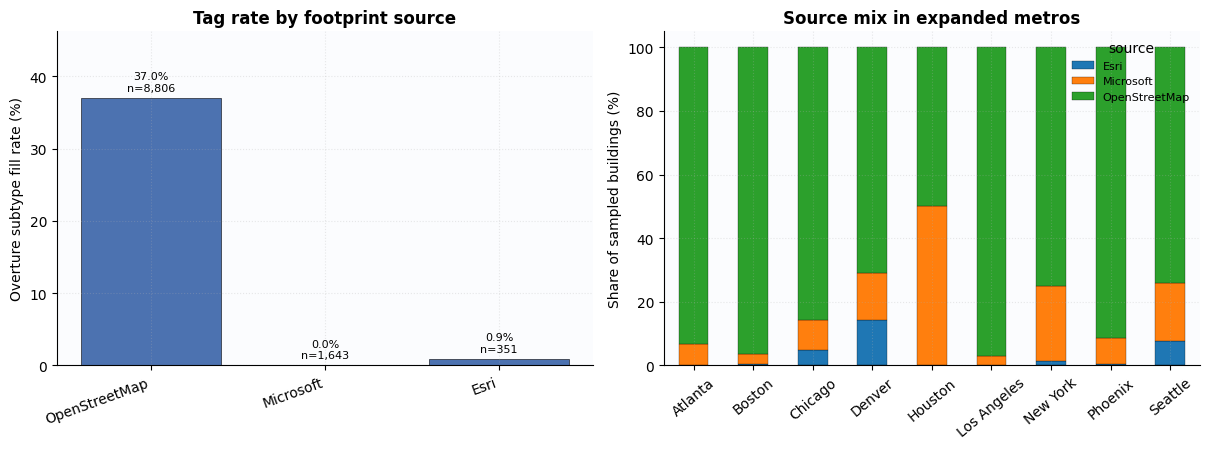

In [4]:
src = (
    base.groupby(["source_family", "labeled"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["labeled", "unlabeled"], fill_value=0)
)
src["n"] = src.sum(axis=1)
src["pct_labeled"] = 100 * src["labeled"] / src["n"].replace(0, np.nan)
src = src.sort_values("n", ascending=False)
src.to_csv(OUT_DIR / "source_vs_labeled.csv")
print(src)

src_region = (
    base.groupby(["region", "source_family"])
    .agg(n=("id", "size"), pct_labeled=("has_subtype", "mean"))
    .reset_index()
)
src_region["pct_labeled"] *= 100
src_region["city"] = src_region["region"].map(REGION_LABELS)

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.6))
ax = axes[0]
fam = src.index.tolist()
ax.bar(np.arange(len(fam)), src["pct_labeled"], color="#4c72b0", edgecolor="k", linewidth=0.4)
ax.set_xticks(np.arange(len(fam)), fam, rotation=20, ha="right")
ax.set_ylabel("Overture subtype fill rate (%)")
ax.set_title("Tag rate by footprint source")
ax.set_ylim(0, max(15.0, float(src["pct_labeled"].max()) * 1.25))
for i, (fam_name, r) in enumerate(src.iterrows()):
    ax.text(i, r["pct_labeled"] + 1.0, f"{r['pct_labeled']:.1f}%\nn={int(r['n']):,}", ha="center", fontsize=8)

ax = axes[1]
mix = base.groupby(["region", "source_family"]).size().unstack(fill_value=0)
mix.index = [REGION_LABELS.get(i, i) for i in mix.index]
mix = 100 * mix.div(mix.sum(axis=1), axis=0)
mix.plot(kind="bar", stacked=True, ax=ax, edgecolor="k", linewidth=0.2)
ax.set_ylabel("Share of sampled buildings (%)")
ax.set_title("Source mix in expanded metros")
ax.tick_params(axis="x", rotation=40)
ax.legend(title="source", frameon=False, fontsize=8)
fig.tight_layout()
savefig(fig, "sources_vs_fill.png")
plt.show()


## 4. Earth Engine helpers + GHSL Degree of Urbanization

Same 1 km GHS-SMOD rollup as notebook 09 (`urban` / `peri_urban` / `rural`). Used only as a stratum for the bias tables.


In [5]:
def init_ee(project: str) -> None:
    if not project or project == "YOUR_EE_PROJECT_ID":
        raise ValueError("Set EE_PROJECT to your Earth Engine Cloud project id.")
    try:
        ee.Initialize(project=project)
    except Exception:
        ee.Authenticate(auth_mode="notebook")
        ee.Initialize(project=project)
    print("Earth Engine initialized ·", project)


def reduce_points(img: ee.Image, df: pd.DataFrame, scale: int, batch_size: int, prop: str):
    rows = []
    n = len(df)
    work = df.reset_index(drop=True)
    for start in range(0, n, batch_size):
        batch = work.iloc[start : start + batch_size]
        feats = []
        for i, r in batch.iterrows():
            feats.append(ee.Feature(ee.Geometry.Point([float(r["lon"]), float(r["lat"])]), {"row_ix": int(i)}))
        sampled = img.reduceRegions(
            collection=ee.FeatureCollection(feats),
            reducer=ee.Reducer.first(),
            scale=scale,
            tileScale=4,
        )
        print(f"  EE {prop} {start}:{start + len(batch)} / {n}", flush=True)
        info = sampled.getInfo()
        for f in info["features"]:
            p = f["properties"]
            val = p.get(prop, p.get("first"))
            rows.append({"row_ix": p.get("row_ix"), prop: val})
        time.sleep(0.2)
    return pd.DataFrame(rows)


def sample_smod(df: pd.DataFrame) -> pd.DataFrame:
    init_ee(EE_PROJECT)
    img = ee.Image(f"JRC/GHSL/P2023A/GHS_SMOD_V2-0/{SMOD_YEAR}").select("smod_code")
    raw = reduce_points(img, df, scale=1000, batch_size=EE_BATCH, prop="smod_code")
    out = df.reset_index(drop=True).copy()
    if len(raw):
        mapped = raw.set_index("row_ix")["smod_code"]
        out.loc[mapped.index.intersection(out.index), "smod_code"] = mapped.reindex(out.index)
    return attach_dou(out)


if "dou" in base.columns and base["dou"].notna().mean() > 0.8:
    print("DoU already present on", float(base["dou"].notna().mean()), "of rows")
else:
    dou_path = OUT_DIR / "base_with_dou.parquet"
    if dou_path.exists():
        base = pd.read_parquet(dou_path)
        print("Loaded cached DoU")
    else:
        base = sample_smod(base)
        base.to_parquet(dou_path, index=False)
        print("Wrote", dou_path)

print(base.groupby("dou", dropna=False).size())


DoU already present on 1.0 of rows
dou
peri_urban    2098
rural         1010
urban         7692
dtype: int64


## 5. FEMA / ORNL USA Structures — `OCC_CLS`

Nationwide occupancy on structures ≥ 450 sq ft ([GEE community catalog](https://gee-community-catalog.org/projects/usa_structures/), [Scientific Data](https://www.nature.com/articles/s41597-024-03219-x)). `OCC_CLS = Residential` is the independent residential flag.

We rasterize state feature collections in each hinterland and sample at the Overture centroid (~10 m). That is a spatial join, not an ID join.


In [6]:
FEMA_PREFIXES = ("USA_ST_", "US_ST_")
FEMA_ASSET_ROOT = "projects/sat-io/open-datasets/ORNL/USA-STRUCTURES"
FEMA_ASSETS: dict[str, str] = {}


def resolve_fema_asset(state: str) -> str | None:
    if state in FEMA_ASSETS:
        return FEMA_ASSETS[state] or None
    for prefix in FEMA_PREFIXES:
        aid = f"{FEMA_ASSET_ROOT}/{prefix}{state}"
        try:
            ee.FeatureCollection(aid).limit(1).first().getInfo()
            FEMA_ASSETS[state] = aid
            print("  FEMA asset", aid)
            return aid
        except Exception:
            continue
    FEMA_ASSETS[state] = ""
    print("  no FEMA asset for", state)
    return None


def fema_res_image(states: list[str], geom: ee.Geometry) -> ee.Image:
    imgs = []
    for st in states:
        aid = resolve_fema_asset(st)
        if not aid:
            continue
        fc = ee.FeatureCollection(aid).filterBounds(geom)
        fc = fc.map(
            lambda f: f.set(
                "fema_res",
                ee.Algorithms.If(
                    f.get("OCC_CLS"),
                    ee.Algorithms.If(
                        ee.String(f.get("OCC_CLS")).toLowerCase().index("residential").eq(0),
                        1,
                        0,
                    ),
                    0,
                ),
            )
        )
        imgs.append(fc.reduceToImage(["fema_res"], ee.Reducer.first()).rename("fema_res"))
    if not imgs:
        return ee.Image.constant(-1).rename("fema_res")
    return ee.ImageCollection(imgs).mosaic().rename("fema_res")


fema_path = OUT_DIR / "base_with_fema.parquet"
if fema_path.exists():
    base = pd.read_parquet(fema_path)
    print("Loaded cached FEMA join")
else:
    init_ee(EE_PROJECT)
    frames = []
    for name, bbox in US_REGIONS.items():
        hb = expand_bbox(bbox)
        geom = ee.Geometry.Rectangle(list(hb), None, False)
        print(f"FEMA · {REGION_LABELS[name]} · {REGION_STATES[name]}", flush=True)
        img = fema_res_image(REGION_STATES[name], geom)
        part = base[base["region"] == name].copy()
        raw = reduce_points(img, part, scale=10, batch_size=EE_BATCH, prop="fema_res")
        part = part.reset_index(drop=True)
        part["fema_res"] = np.nan
        if len(raw):
            mapped = pd.to_numeric(raw.set_index("row_ix")["fema_res"], errors="coerce")
            part.loc[mapped.index.intersection(part.index), "fema_res"] = mapped
        frames.append(part)
    base = pd.concat(frames, ignore_index=True)
    base.to_parquet(fema_path, index=False)
    print("Wrote", fema_path)

base["fema_res"] = pd.to_numeric(base["fema_res"], errors="coerce")
base["fema_hit"] = base["fema_res"].isin([0, 1])
print("FEMA match rate:", float(base["fema_hit"].mean()))
print(base.loc[base["fema_hit"], "fema_res"].value_counts())


Earth Engine initialized · ee-kedarvaidya0504
FEMA · Boston · ['MA', 'NH', 'RI']
  FEMA asset projects/sat-io/open-datasets/ORNL/USA-STRUCTURES/USA_ST_MA
  FEMA asset projects/sat-io/open-datasets/ORNL/USA-STRUCTURES/USA_ST_NH
  FEMA asset projects/sat-io/open-datasets/ORNL/USA-STRUCTURES/USA_ST_RI
  EE fema_res 0:800 / 1200
  EE fema_res 800:1200 / 1200
FEMA · New York · ['NY', 'NJ', 'CT']
  FEMA asset projects/sat-io/open-datasets/ORNL/USA-STRUCTURES/USA_ST_NY
  FEMA asset projects/sat-io/open-datasets/ORNL/USA-STRUCTURES/USA_ST_NJ
  FEMA asset projects/sat-io/open-datasets/ORNL/USA-STRUCTURES/USA_ST_CT
  EE fema_res 0:800 / 1200
  EE fema_res 800:1200 / 1200
FEMA · Chicago · ['IL', 'IN']
  FEMA asset projects/sat-io/open-datasets/ORNL/USA-STRUCTURES/USA_ST_IL
  FEMA asset projects/sat-io/open-datasets/ORNL/USA-STRUCTURES/USA_ST_IN
  EE fema_res 0:800 / 1200
  EE fema_res 800:1200 / 1200
FEMA · Atlanta · ['GA']
  FEMA asset projects/sat-io/open-datasets/ORNL/USA-STRUCTURES/USA_ST_GA


### 5.1 P(residential | labeled) vs P(residential | unlabeled) — FEMA


FEMA occupancy among Overture-labeled vs unlabeled buildings
    region  n_labeled  n_unlabeled  pct_res_labeled  pct_res_unlabeled  delta_unlab_minus_lab        city
Atlanta_SE    270.000      717.000           93.333             94.282                  0.948     Atlanta
 Boston_NE     64.000      890.000            0.000              0.000                  0.000      Boston
Chicago_MW    211.000      777.000            0.000              0.000                  0.000     Chicago
  Denver_W    400.000      626.000            0.000              0.000                  0.000      Denver
 Houston_S     82.000      929.000           91.463             93.541                  2.078     Houston
      LA_W    856.000      197.000            0.000              0.000                  0.000 Los Angeles
    NYC_NE    267.000      798.000            0.000              0.000                  0.000    New York
Phoenix_SW    472.000      610.000            0.000              0.000                  0.0

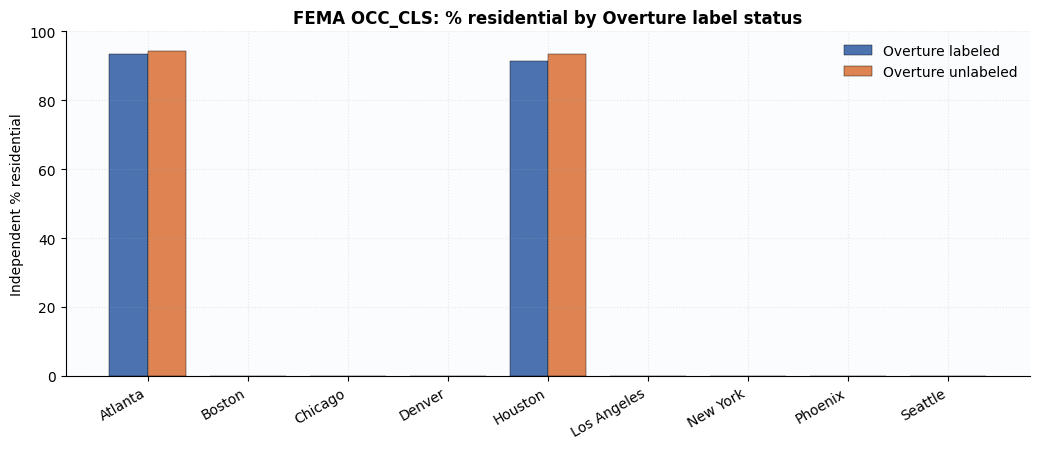

Saved /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/week2_missingness/fema_bias_by_dou.png


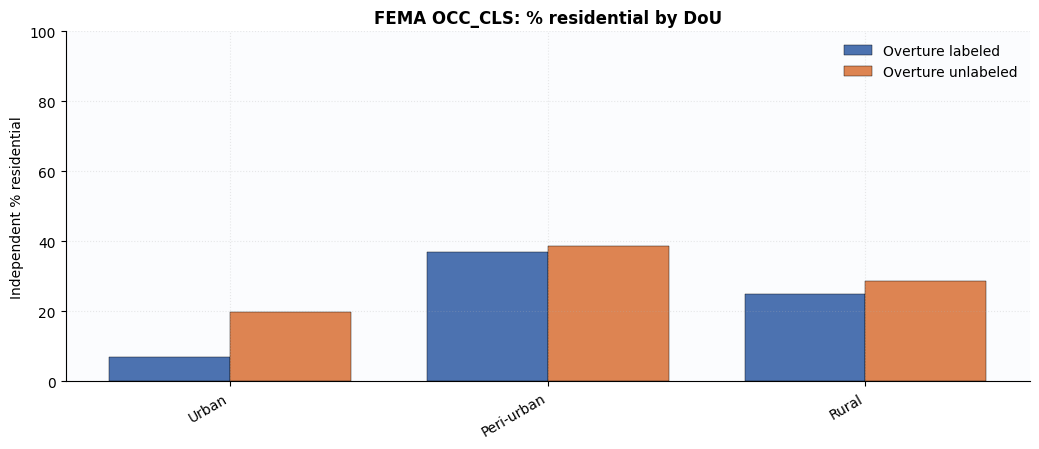

In [7]:
def bias_table(df: pd.DataFrame, ycol: str, hitcol: str, group: str | None = None) -> pd.DataFrame:
    work = df[df[hitcol]].copy()
    work["_y"] = pd.to_numeric(work[ycol], errors="coerce")
    work = work[work["_y"].isin([0, 1])]
    keys = ["labeled"] if group is None else [group, "labeled"]
    tab = (
        work.groupby(keys)
        .agg(n=("id", "size"), pct_res=("_y", "mean"))
        .reset_index()
    )
    tab["pct_res"] *= 100
    if group is None:
        wide = tab.pivot(index="labeled", columns="labeled", values="pct_res")  # placeholder
        labeled = tab.set_index("labeled")
        out = pd.DataFrame({
            "n_labeled": [int(labeled.loc["labeled", "n"]) if "labeled" in labeled.index else 0],
            "n_unlabeled": [int(labeled.loc["unlabeled", "n"]) if "unlabeled" in labeled.index else 0],
            "pct_res_labeled": [float(labeled.loc["labeled", "pct_res"]) if "labeled" in labeled.index else np.nan],
            "pct_res_unlabeled": [float(labeled.loc["unlabeled", "pct_res"]) if "unlabeled" in labeled.index else np.nan],
        })
        out["delta_unlab_minus_lab"] = out["pct_res_unlabeled"] - out["pct_res_labeled"]
        return out
    wide = tab.pivot(index=group, columns="labeled", values=["n", "pct_res"])
    wide.columns = [f"{a}_{b}" for a, b in wide.columns]
    wide = wide.reset_index()
    if "pct_res_labeled" in wide.columns and "pct_res_unlabeled" in wide.columns:
        wide["delta_unlab_minus_lab"] = wide["pct_res_unlabeled"] - wide["pct_res_labeled"]
    return wide


def plot_bias(tab: pd.DataFrame, title: str, fname: str, label_col: str = "city"):
    fig, ax = plt.subplots(figsize=(10.5, 4.6))
    x = np.arange(len(tab))
    w = 0.38
    ax.bar(x - w / 2, tab["pct_res_labeled"], w, label="Overture labeled", color="#4c72b0", edgecolor="k", linewidth=0.3)
    ax.bar(x + w / 2, tab["pct_res_unlabeled"], w, label="Overture unlabeled", color="#dd8452", edgecolor="k", linewidth=0.3)
    ax.set_xticks(x, tab[label_col], rotation=30, ha="right")
    ax.set_ylabel("Independent % residential")
    ax.set_ylim(0, 100)
    ax.set_title(title)
    ax.legend(frameon=False)
    fig.tight_layout()
    savefig(fig, fname)
    plt.show()


fema_city = bias_table(base, "fema_res", "fema_hit", group="region")
fema_city["city"] = fema_city["region"].map(REGION_LABELS)
fema_city = fema_city.sort_values("city")
fema_city.to_csv(OUT_DIR / "fema_bias_by_city.csv", index=False)
print("FEMA occupancy among Overture-labeled vs unlabeled buildings")
print(fema_city.to_string(index=False))

fema_dou = bias_table(base, "fema_res", "fema_hit", group="dou")
if "dou" in fema_dou.columns:
    fema_dou = fema_dou.set_index("dou").reindex(DOU_ORDER).reset_index()
    fema_dou["city"] = fema_dou["dou"].map(DOU_LABELS)
fema_dou.to_csv(OUT_DIR / "fema_bias_by_dou.csv", index=False)
print("\nBy degree of urbanization")
print(fema_dou.to_string(index=False))

plot_bias(fema_city, "FEMA OCC_CLS: % residential by Overture label status", "fema_bias_by_city.png")
if "pct_res_labeled" in fema_dou.columns:
    plot_bias(fema_dou.dropna(subset=["pct_res_labeled"]), "FEMA OCC_CLS: % residential by DoU", "fema_bias_by_dou.png")


## 6. GHS-OBAT — `use` (1 = residential, 2 = non-residential)

[GHS-OBAT R2024A](https://gee-community-catalog.org/projects/ghs_obat/) attaches GHSL function to ~2.3B Overture footprints (built on release `2024-07-22.0`). Two joins:

1. **GERS id** — exact, but IDs drift across Overture releases.
2. **Centroid spatial** — `reduceToImage` on `use`, sampled at 30 m. This is the fallback and the one we trust for the bias table.

`use = 1` → residential; `use = 2` → non-residential; `0` dropped.


Earth Engine initialized · ee-kedarvaidya0504
GHS-OBAT · Boston
  EE obat_res 0:800 / 1200
  EE obat_res 800:1200 / 1200
GHS-OBAT · New York
  EE obat_res 0:800 / 1200
  EE obat_res 800:1200 / 1200
GHS-OBAT · Chicago
  EE obat_res 0:800 / 1200
  EE obat_res 800:1200 / 1200
GHS-OBAT · Atlanta
  EE obat_res 0:800 / 1200
  EE obat_res 800:1200 / 1200
GHS-OBAT · Houston
  EE obat_res 0:800 / 1200
  EE obat_res 800:1200 / 1200
GHS-OBAT · Denver
  EE obat_res 0:800 / 1200
  EE obat_res 800:1200 / 1200
GHS-OBAT · Phoenix
  EE obat_res 0:800 / 1200
  EE obat_res 800:1200 / 1200
GHS-OBAT · Seattle
  EE obat_res 0:800 / 1200
  EE obat_res 800:1200 / 1200
GHS-OBAT · Los Angeles
  EE obat_res 0:800 / 1200
  EE obat_res 800:1200 / 1200
Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/week2_missingness/base_with_obat.parquet
GERS id match rate by city (expect low across releases): [('Boston_NE', 0.0), ('NYC_NE', 0.0), ('Chicago_MW', 0.0), ('Atlanta_SE', 0.0), ('Houston_S', 0.0), ('Den

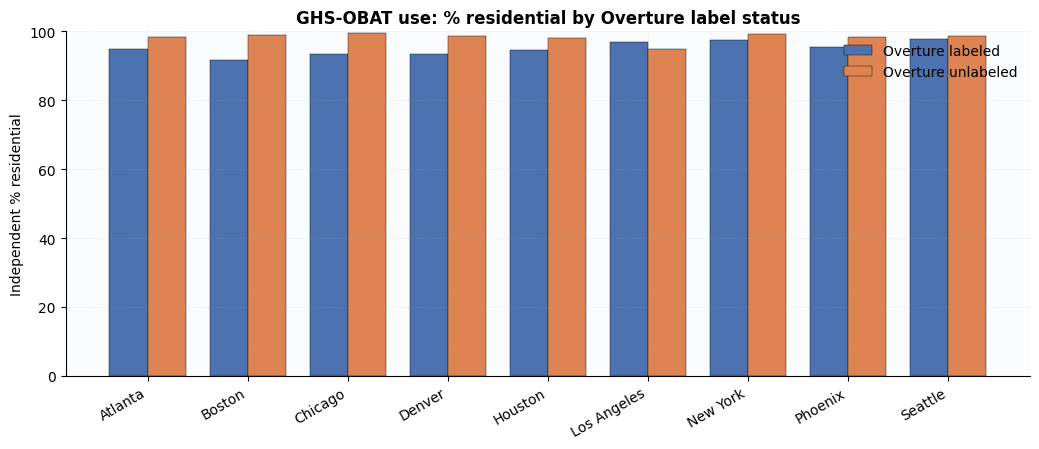

In [8]:
OBAT_USA = "projects/sat-io/open-datasets/JRC/GHS-OBAT/GHS_OBAT_GPKG_USA_E2020_R2024A_V1_0"


def gers_key(oid: str) -> str:
    s = str(oid).replace("-", "").lower()
    hexpart = "".join(ch for ch in s if ch in "0123456789abcdef")
    return hexpart[-32:] if len(hexpart) >= 32 else hexpart


def obat_use_image(geom: ee.Geometry) -> ee.Image:
    fc = ee.FeatureCollection(OBAT_USA).filterBounds(geom)
    fc = fc.filter(ee.Filter.inList("use", [1, 2]))
    fc = fc.map(lambda f: f.set("obat_res", ee.Algorithms.If(ee.Number(f.get("use")).eq(1), 1, 0)))
    return fc.reduceToImage(["obat_res"], ee.Reducer.first()).rename("obat_res")


def obat_id_lookup(df: pd.DataFrame, geom: ee.Geometry, batch: int = 200) -> pd.Series:
    # Match rate diagnostic - not the primary bias join.
    fc = ee.FeatureCollection(OBAT_USA).filterBounds(geom)
    keys = df["gers"].tolist()
    found = {}
    for start in range(0, len(keys), batch):
        chunk = keys[start : start + batch]
        sub = fc.filter(ee.Filter.inList("id", chunk)).select(["id", "use"]).getInfo()
        for f in sub.get("features", []):
            p = f["properties"]
            found[str(p.get("id")).lower()] = p.get("use")
        time.sleep(0.15)
    return df["gers"].map(lambda k: found.get(str(k).lower()))


obat_path = OUT_DIR / "base_with_obat.parquet"
if obat_path.exists():
    base = pd.read_parquet(obat_path)
    print("Loaded cached GHS-OBAT join")
else:
    init_ee(EE_PROJECT)
    base["gers"] = base["id"].map(gers_key)
    frames = []
    id_hits = []
    for name, bbox in US_REGIONS.items():
        hb = expand_bbox(bbox)
        geom = ee.Geometry.Rectangle(list(hb), None, False)
        print(f"GHS-OBAT · {REGION_LABELS[name]}", flush=True)
        part = base[base["region"] == name].copy().reset_index(drop=True)
        img = obat_use_image(geom)
        raw = reduce_points(img, part, scale=30, batch_size=EE_BATCH, prop="obat_res")
        part["obat_res"] = np.nan
        if len(raw):
            mapped = pd.to_numeric(raw.set_index("row_ix")["obat_res"], errors="coerce")
            part.loc[mapped.index.intersection(part.index), "obat_res"] = mapped
        try:
            part["obat_use_id"] = obat_id_lookup(part, geom)
            id_hits.append((name, float(part["obat_use_id"].notna().mean())))
        except Exception as exc:
            part["obat_use_id"] = np.nan
            print("  id join skipped:", exc)
        frames.append(part)
    base = pd.concat(frames, ignore_index=True)
    base.to_parquet(obat_path, index=False)
    print("Wrote", obat_path)
    if id_hits:
        print("GERS id match rate by city (expect low across releases):", id_hits)

base["obat_res"] = pd.to_numeric(base["obat_res"], errors="coerce")
base["obat_hit"] = base["obat_res"].isin([0, 1])
print("GHS-OBAT spatial match rate:", float(base["obat_hit"].mean()))
if "obat_use_id" in base.columns:
    print("GERS id match rate:", float(base["obat_use_id"].notna().mean()))

obat_city = bias_table(base, "obat_res", "obat_hit", group="region")
obat_city["city"] = obat_city["region"].map(REGION_LABELS)
obat_city = obat_city.sort_values("city")
obat_city.to_csv(OUT_DIR / "obat_bias_by_city.csv", index=False)
print(obat_city.to_string(index=False))

obat_dou = bias_table(base, "obat_res", "obat_hit", group="dou")
if "dou" in obat_dou.columns:
    obat_dou = obat_dou.set_index("dou").reindex(DOU_ORDER).reset_index()
    obat_dou["city"] = obat_dou["dou"].map(DOU_LABELS)
obat_dou.to_csv(OUT_DIR / "obat_bias_by_dou.csv", index=False)

plot_bias(obat_city, "GHS-OBAT use: % residential by Overture label status", "obat_bias_by_city.png")


## 7. Overture Places — institutional / commercial POIs on unlabeled buildings

If an unlabeled footprint sits under a school, hospital, or shop, the missing tag is not a random hole. Places are noisier than FEMA (home businesses, campus collisions) but they travel globally.

Join: nearest Place within 40 m of the building centroid. Non-residential signal = Places `taxonomy.hierarchy[1]` in education, health care, retail, dining, etc.


Places · Boston
  217,529 POIs · 194 buildings within 40 m
Places · New York
  680,971 POIs · 308 buildings within 40 m
Places · Chicago
  335,963 POIs · 171 buildings within 40 m
Places · Atlanta
  259,593 POIs · 117 buildings within 40 m
Places · Houston
  330,776 POIs · 142 buildings within 40 m
Places · Denver
  172,866 POIs · 144 buildings within 40 m
Places · Phoenix
  205,216 POIs · 124 buildings within 40 m
Places · Seattle
  170,221 POIs · 154 buildings within 40 m
Places · Los Angeles
  530,754 POIs · 197 buildings within 40 m
Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/week2_missingness/base_with_places.parquet
Share of buildings with a non-residential Place within 40 m
    region  n_labeled  n_unlabeled  pct_poi_labeled  pct_poi_unlabeled  pct_nr_poi_labeled  pct_nr_poi_unlabeled        city  delta_nr_poi
Atlanta_SE    330.000      870.000           12.727              8.621              11.905                 5.333     Atlanta        -6.571
 Boston_NE  

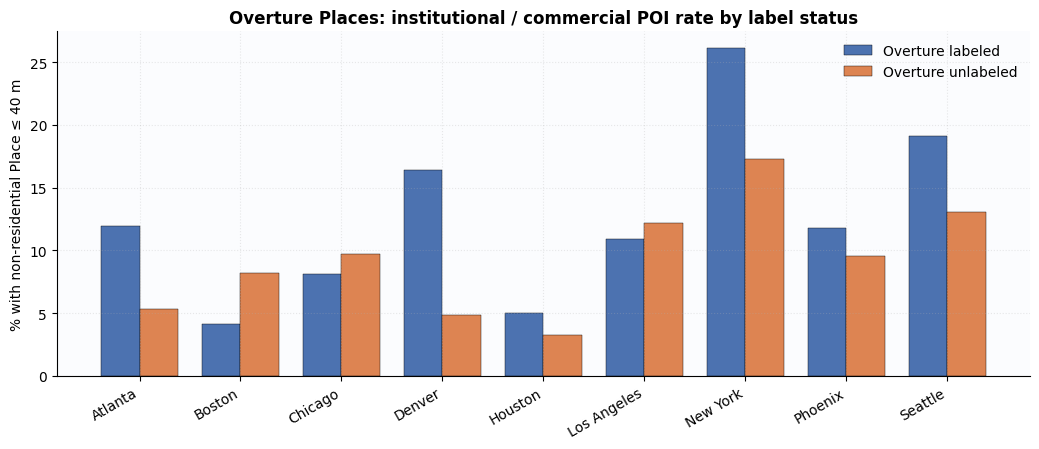


Top Places L0 on unlabeled buildings
place_l0
services_and_business        353
shopping                     130
food_and_drink                75
lifestyle_services            73
travel_and_transportation     70
cultural_and_historic         62
health_care                   50
community_and_government      46
sports_and_recreation         43
education                     35
arts_and_entertainment        22
lodging                       16
Name: count, dtype: int64


In [9]:
def sample_places(con, name: str, bbox) -> pd.DataFrame:
    xmin, ymin, xmax, ymax = bbox
    sql = f'''
    SELECT
      id AS place_id,
      '{name}' AS region,
      taxonomy.hierarchy[1] AS l0,
      basic_category,
      ST_X(geometry) AS lon,
      ST_Y(geometry) AS lat
    FROM read_parquet('{PLACES}', hive_partitioning=1)
    WHERE bbox.xmin BETWEEN {xmin} AND {xmax}
      AND bbox.ymin BETWEEN {ymin} AND {ymax}
      AND geometry IS NOT NULL
    '''
    return con.execute(sql).df()


def nearest_join(left: pd.DataFrame, right: pd.DataFrame, radius_m: float, prefix: str) -> pd.DataFrame:
    out = left.copy()
    out[f"{prefix}_id"] = pd.NA
    out[f"{prefix}_l0"] = pd.NA
    out[f"{prefix}_m"] = np.nan
    if right.empty or left.empty:
        return out
    # local meters: 1 deg lat ~ 111_111 m; lon scaled by cos(lat)
    lat0 = float(left["lat"].mean())
    kx = 111_111.0 * np.cos(np.radians(lat0))
    ky = 111_111.0
    xy_r = np.c_[right["lon"].to_numpy() * kx, right["lat"].to_numpy() * ky]
    xy_l = np.c_[left["lon"].to_numpy() * kx, left["lat"].to_numpy() * ky]
    nn = NearestNeighbors(n_neighbors=1, algorithm="kd_tree")
    nn.fit(xy_r)
    dist, idx = nn.kneighbors(xy_l)
    dist = dist[:, 0]
    idx = idx[:, 0]
    hit = dist <= radius_m
    if hit.any():
        take = right.iloc[idx[hit]]
        out.loc[out.index[hit], f"{prefix}_id"] = take["place_id"].to_numpy()
        out.loc[out.index[hit], f"{prefix}_l0"] = take["l0"].to_numpy()
        out.loc[out.index[hit], f"{prefix}_m"] = dist[hit]
    return out


places_path = OUT_DIR / "base_with_places.parquet"
if places_path.exists():
    base = pd.read_parquet(places_path)
    print("Loaded cached Places join")
else:
    con = duck()
    frames = []
    for name, bbox in US_REGIONS.items():
        hb = expand_bbox(bbox)
        print(f"Places · {REGION_LABELS[name]}", flush=True)
        pois = sample_places(con, name, hb)
        part = base[base["region"] == name].copy().reset_index(drop=True)
        frames.append(nearest_join(part, pois, PLACE_RADIUS_M, "place"))
        print(f"  {len(pois):,} POIs · {int(frames[-1]['place_id'].notna().sum())} buildings within {PLACE_RADIUS_M} m")
    base = pd.concat(frames, ignore_index=True)
    base.to_parquet(places_path, index=False)
    print("Wrote", places_path)

base["place_hit"] = base["place_id"].notna()
base["place_nonres"] = base["place_l0"].isin(PLACE_NONRES_L0).astype(float)
base.loc[~base["place_hit"], "place_nonres"] = np.nan

place_city = (
    base.groupby(["region", "labeled"])
    .agg(n=("id", "size"), pct_poi=("place_hit", "mean"), pct_nr_poi=("place_nonres", "mean"))
    .reset_index()
)
place_city["pct_poi"] *= 100
place_city["pct_nr_poi"] *= 100
wide = place_city.pivot(index="region", columns="labeled", values=["n", "pct_poi", "pct_nr_poi"])
wide.columns = [f"{a}_{b}" for a, b in wide.columns]
wide = wide.reset_index()
wide["city"] = wide["region"].map(REGION_LABELS)
wide["delta_nr_poi"] = wide.get("pct_nr_poi_unlabeled", np.nan) - wide.get("pct_nr_poi_labeled", np.nan)
wide.to_csv(OUT_DIR / "places_bias_by_city.csv", index=False)
print("Share of buildings with a non-residential Place within 40 m")
print(wide.to_string(index=False))

fig, ax = plt.subplots(figsize=(10.5, 4.6))
x = np.arange(len(wide))
w = 0.38
ax.bar(x - w / 2, wide["pct_nr_poi_labeled"], w, label="Overture labeled", color="#4c72b0", edgecolor="k", linewidth=0.3)
ax.bar(x + w / 2, wide["pct_nr_poi_unlabeled"], w, label="Overture unlabeled", color="#dd8452", edgecolor="k", linewidth=0.3)
ax.set_xticks(x, wide["city"], rotation=30, ha="right")
ax.set_ylabel("% with non-residential Place ≤ 40 m")
ax.set_title("Overture Places: institutional / commercial POI rate by label status")
ax.legend(frameon=False)
fig.tight_layout()
savefig(fig, "places_bias_by_city.png")
plt.show()

print("\nTop Places L0 on unlabeled buildings")
print(base.loc[base["labeled"].eq("unlabeled") & base["place_hit"], "place_l0"].value_counts().head(12))


## 8. NYC MapPLUTO — cadastral check (New York only)

[PLUTO / MapPLUTO](https://www.nyc.gov/site/planning/data-maps/open-data/dwn-pluto-mappluto.page) is the highest-accuracy open US assessor layer we can grab this week. LandUse **01–03** = residential; **04** = mixed; **05+** = non-residential.

First cut: nearest tax lot centroid within 60 m, clipped to the NYC box (the hinterland spills into NJ / CT, which PLUTO does not cover). Polygon intersection can replace this later.


In [10]:
def fetch_pluto(bbox) -> pd.DataFrame:
    xmin, ymin, xmax, ymax = bbox
    # Socrata PLUTO (64uk-42ks) — tabular lots with lat/lon
    where = quote(
        f"latitude >= {ymin} AND latitude <= {ymax} "
        f"AND longitude >= {xmin} AND longitude <= {xmax}"
    )
    url = (
        "https://data.cityofnewyork.us/resource/64uk-42ks.json"
        f"?$select=bbl,address,landuse,bldgclass,latitude,longitude"
        f"&$where={where}&$limit=50000"
    )
    print("Downloading PLUTO", url[:90], "...", flush=True)
    with urlopen(url, timeout=120) as resp:
        rows = json.loads(resp.read().decode("utf-8"))
    df = pd.DataFrame(rows)
    if df.empty:
        return df
    df = df.rename(columns={"latitude": "lat", "longitude": "lon", "landuse": "l0"})
    df["lon"] = pd.to_numeric(df["lon"], errors="coerce")
    df["lat"] = pd.to_numeric(df["lat"], errors="coerce")
    df["place_id"] = df.get("bbl")
    df["l0"] = df["l0"].astype(str).str.zfill(2)
    return df.dropna(subset=["lon", "lat"])


def pluto_res_flag(code) -> float:
    if pd.isna(code):
        return np.nan
    c = str(code).zfill(2)
    if c in PLUTO_RES:
        return 1.0
    if c in PLUTO_MIXED:
        return np.nan
    if c in {"05", "06", "07", "08", "09", "10", "11"}:
        return 0.0
    return np.nan


pluto_path = OUT_DIR / "base_with_pluto.parquet"
if pluto_path.exists():
    base = pd.read_parquet(pluto_path)
    print("Loaded cached PLUTO join")
else:
    nyc_mask = (
        (base["region"] == "NYC_NE")
        & base["lon"].between(NYC_BOX[0], NYC_BOX[2])
        & base["lat"].between(NYC_BOX[1], NYC_BOX[3])
    )
    nyc = base.loc[nyc_mask].copy().reset_index(drop=True)
    lots = fetch_pluto(NYC_BOX)
    print("PLUTO lots:", len(lots))
    if len(lots) and len(nyc):
        joined = nearest_join(nyc, lots, PLUTO_RADIUS_M, "pluto")
        joined["pluto_landuse"] = joined["pluto_l0"]
    else:
        joined = nyc
        joined["pluto_landuse"] = pd.NA
        joined["pluto_id"] = pd.NA
        joined["pluto_m"] = np.nan
    other = base.loc[~nyc_mask].copy()
    for col in ("pluto_id", "pluto_l0", "pluto_m", "pluto_landuse"):
        if col not in other.columns:
            other[col] = pd.NA if col != "pluto_m" else np.nan
    base = pd.concat([joined, other], ignore_index=True)
    base.to_parquet(pluto_path, index=False)
    print("Wrote", pluto_path)

base["pluto_res"] = base.get("pluto_landuse", pd.Series(index=base.index)).map(pluto_res_flag)
base["pluto_hit"] = base["pluto_res"].isin([0, 1])
print("NYC PLUTO match rate (NYC-box buildings):", float(base.loc[base["region"].eq("NYC_NE"), "pluto_hit"].mean()))

pluto_tab = bias_table(base[base["region"].eq("NYC_NE")], "pluto_res", "pluto_hit", group="region")
pluto_tab["city"] = "New York"
pluto_tab.to_csv(OUT_DIR / "pluto_bias_nyc.csv", index=False)
print(pluto_tab.to_string(index=False))
print("\nPLUTO LandUse on unlabeled NYC buildings")
print(
    base.loc[base["region"].eq("NYC_NE") & base["labeled"].eq("unlabeled"), "pluto_landuse"]
    .value_counts(dropna=False)
    .head(12)
)


PLUTO lots: 50000
Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/week2_missingness/base_with_pluto.parquet
NYC PLUTO match rate (NYC-box buildings): 0.0425
region  n_labeled  n_unlabeled  pct_res_labeled  pct_res_unlabeled  delta_unlab_minus_lab     city
NYC_NE     11.000       40.000           63.636             77.500                 13.864 New York

PLUTO LandUse on unlabeled NYC buildings
pluto_landuse
<NA>    505
NaN     344
01       18
02       11
04        5
08        3
03        2
11        2
07        2
09        1
05        1
Name: count, dtype: int64


## 9. Read-out — coverage gap or class bias?

Working rule: labels do not need to be perfect; they must not have a **consistent** class bias.

For each independent layer we report \(\Delta = P(\text{res}\mid\text{unlabeled}) - P(\text{res}\mid\text{labeled})\).

| \(|\Delta|\) | Reading |
|---|---|
| small (≲ 8 pp) | Coverage gap. Missingness follows OSM vs ML source mix. Keep unlabeled **out** of training; city can stay in gold/transfer if labeled counts are adequate. |
| large and same sign in every city | Consistent class bias. Do not train as if labeled buildings represent the stock. Down-weight or exclude. |
| large but **sign flips** by city | Same finding as Atwal et al. 2022. City-specific confidence, not a global “OSM misses houses” story. |


   layer        city  pct_res_labeled  pct_res_unlabeled  delta_unlab_minus_lab
    FEMA     Atlanta           93.333             94.282                  0.948
    FEMA      Boston            0.000              0.000                  0.000
    FEMA     Chicago            0.000              0.000                  0.000
    FEMA      Denver            0.000              0.000                  0.000
    FEMA     Houston           91.463             93.541                  2.078
    FEMA Los Angeles            0.000              0.000                  0.000
    FEMA    New York            0.000              0.000                  0.000
    FEMA     Phoenix            0.000              0.000                  0.000
    FEMA     Seattle            0.000              0.000                  0.000
GHS-OBAT     Atlanta           94.805             98.417                  3.611
GHS-OBAT      Boston           91.765             98.982                  7.218
GHS-OBAT     Chicago           93.562   

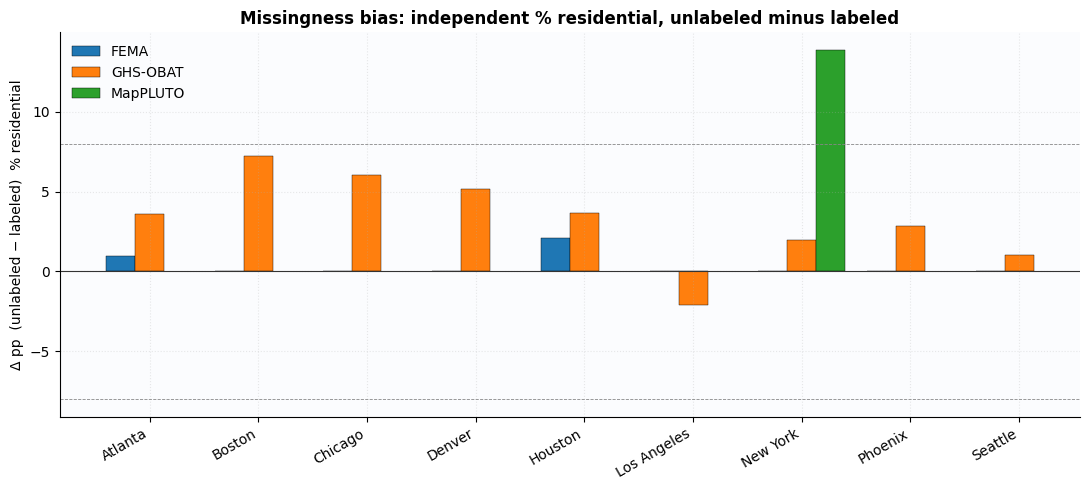

{
  "question": "Are Overture missing use-tags biased toward residential, non-residential, or both?",
  "rule": "Similar P(res) => coverage gap (OSM vs ML). Large delta => class bias enters sampling / city exclusion.",
  "n_buildings": 10800,
  "pct_labeled": 0.3016666666666667,
  "source_fill": {
    "OpenStreetMap": 36.96343402225755,
    "Microsoft": 0.0,
    "Esri": 0.8547008547008547
  },
  "fema_match": 0.8449074074074074,
  "obat_match": 0.9581481481481482,
  "outputs": [
    "base_sample.parquet",
    "base_with_fema.parquet",
    "base_with_obat.parquet",
    "base_with_places.parquet",
    "base_with_pluto.parquet",
    "fema_bias_by_city.csv",
    "fema_bias_by_city.png",
    "fema_bias_by_dou.csv",
    "fema_bias_by_dou.png",
    "missingness_bias_delta.png",
    "missingness_bias_summary.csv",
    "obat_bias_by_city.csv",
    "obat_bias_by_city.png",
    "obat_bias_by_dou.csv",
    "places_bias_by_city.csv",
    "places_bias_by_city.png",
    "pluto_bias_nyc.csv",
    "sou

In [11]:
rows = []
for layer, tab in [("FEMA", fema_city), ("GHS-OBAT", obat_city), ("MapPLUTO", pluto_tab)]:
    if tab is None or len(tab) == 0 or "delta_unlab_minus_lab" not in tab.columns:
        continue
    tmp = tab.copy()
    tmp["layer"] = layer
    if "city" not in tmp.columns and "region" in tmp.columns:
        tmp["city"] = tmp["region"].map(REGION_LABELS)
    rows.append(tmp)

summary = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()
# keep a compact view
view_cols = [c for c in [
    "layer", "city", "pct_res_labeled", "pct_res_unlabeled", "delta_unlab_minus_lab",
] if c in summary.columns]
print(summary[view_cols].sort_values(["layer", "city"]).to_string(index=False))
summary.to_csv(OUT_DIR / "missingness_bias_summary.csv", index=False)

if len(summary):
    fig, ax = plt.subplots(figsize=(11, 5.0))
    layers = list(summary["layer"].unique())
    cities = sorted(summary["city"].dropna().unique())
    x = np.arange(len(cities))
    w = 0.8 / max(len(layers), 1)
    for i, layer in enumerate(layers):
        sub = summary[summary["layer"] == layer].set_index("city").reindex(cities)
        ax.bar(x + (i - (len(layers) - 1) / 2) * w, sub["delta_unlab_minus_lab"], w, label=layer, edgecolor="k", linewidth=0.3)
    ax.axhline(0, color="#333", lw=0.8)
    ax.axhline(8, color="#888", lw=0.6, ls="--")
    ax.axhline(-8, color="#888", lw=0.6, ls="--")
    ax.set_xticks(x, cities, rotation=30, ha="right")
    ax.set_ylabel("Δ pp  (unlabeled − labeled)  % residential")
    ax.set_title("Missingness bias: independent % residential, unlabeled minus labeled")
    ax.legend(frameon=False)
    fig.tight_layout()
    savefig(fig, "missingness_bias_delta.png")
    plt.show()

snap = {
    "question": "Are Overture missing use-tags biased toward residential, non-residential, or both?",
    "rule": "Similar P(res) => coverage gap (OSM vs ML). Large delta => class bias enters sampling / city exclusion.",
    "n_buildings": int(len(base)),
    "pct_labeled": float(base["has_subtype"].mean()),
    "source_fill": src["pct_labeled"].to_dict(),
    "fema_match": float(base["fema_hit"].mean()) if "fema_hit" in base.columns else None,
    "obat_match": float(base["obat_hit"].mean()) if "obat_hit" in base.columns else None,
    "outputs": sorted(p.name for p in OUT_DIR.iterdir()),
}
(OUT_DIR / "week2_missingness_snapshot.json").write_text(json.dumps(snap, indent=2, default=str))
print(json.dumps(snap, indent=2, default=str))


## 10. What this changes in the experiment

1. **Unlabeled footprints stay out of training and evaluation.** Always. A coverage gap is not a class.
2. **If \(\Delta\) is small** after FEMA (and GHS-OBAT agrees), the 9-metro labeled core is usable gold. Report source mix (`sources[]`) so we are not pretending ML roofprints were omitted at random.
3. **If \(\Delta\) is large or flips by city**, city-level confidence goes into the gold / transfer / inference-only rule — not a single national fill-rate cutoff.
4. **Places** is a recall alarm, not gold: unlabeled + school/hospital/shop POI is evidence the hole is structured.
5. **GHS-OBAT** is the layer we will reuse when we leave the US. FEMA is the US check; MapPLUTO is the NYC audit.

**Done when (this notebook):** you can show, for these 9 metros, whether missing tags lean residential, non-residential, or neither — by city and by DoU — and say unlabeled is never a negative.
